# Machine Learning Project

## Miopia Dataset

We start by importing the dependencies for the project and analyzing the data

In [2]:
import pandas as pd
import numpy as np
import matplotlib as mpl
import matplotlib.pyplot as plt
from xgboost import XGBClassifier
from sklearn.preprocessing import LabelEncoder

X_t = pd.read_csv("data/X_train.csv")
Y_t = pd.read_csv("data/Y_train.csv")

We now see the variables in the dataset

In [3]:
X_t.head()

,fecha,edad,sexo,origen antepasados (españa),origen antepasados (extranjeros),hº deporte sem,hº naturaleza sem,hº ocio exteriores sem,horas exterior sem,hº estudiar sem,...,OS-DS,CUVAF-Total,CUVAF-Media,CUVAF-DS,Promedio Nasal,DE Nasal,Suma Nasal,Promedio Temporal,DE Temporal,Suma Temporal
0,2/11/20,22,Mujer,Asturias,NaN,0.0,0.0,4.0,4.0,40,...,0.238059,2.256667,0.564167,0.842300,0.905000,1.279863,1.810000,0.223333,0.160278,0.446667
1,2/17/20,23,Mujer,Navarra,NaN,5.0,2.0,2.0,9.0,20,...,2.585654,8.026667,2.006667,1.887316,3.620833,0.503224,7.241667,0.392500,0.102530,0.785000
2,3/10/20,22,Mujer,Bizkaia,NaN,2.0,3.0,8.0,13.0,30,...,0.431335,12.710000,3.177500,0.743668,3.152500,1.248043,6.305000,3.202500,0.314663,6.405000
3,2/26/20,22,Mujer,"Navarra, Extremadura, Cataluña, Aragón",España,0.0,2.0,13.0,15.0,54,...,0.626968,3.551667,0.887917,0.877145,1.003333,1.418928,2.006667,0.772500,0.491439,1.545000
4,2/19/20,23,Mujer,Toledo,NaN,3.0,0.0,0.0,3.0,56,...,1.269257,1.795000,0.448750,0.897500,0.897500,1.269257,1.795000,0.000000,0.000000,0.000000


In [4]:
Y_t.head()

,M,MM,Combo,DCombo
0,SI,SI,MM,MM
1,SI,NO,M,M1
2,NO,NO,C,C
3,NO,NO,C,C
4,NO,NO,C,C


In [5]:
list(X_t.columns)

['fecha',
 'edad',
 'sexo',
 'origen antepasados (españa)',
 'origen antepasados (extranjeros)',
 'hº deporte sem',
 'hº naturaleza sem',
 'hº ocio exteriores sem',
 'horas exterior sem',
 'hº estudiar sem',
 'hº ocio inter sem',
 'hº act.cerca sem',
 'horas interior sem',
 'Ratio Cerca/Lejos',
 'Exterior Mucho',
 'Interior Mcho',
 'fototipo',
 'Grupo fot',
 'familiar miope',
 'Familiar miope num.',
 'Familiar MM SI/NO',
 'familiar miope magno',
 'pat. Ret. Miop magna',
 'fumador',
 'toma sol',
 'protege sol',
 'disp.elec.antes dormir',
 'LA OD',
 'LA OS',
 'LA Media',
 'Querato OD',
 'Querato OD Eje2',
 'Querato OS',
 'Querato OS Eje 2',
 'OD-Total',
 'OD-Media',
 'OD-DS',
 'OS-Total',
 'OS-Media',
 'OS-DS',
 'CUVAF-Total',
 'CUVAF-Media',
 'CUVAF-DS',
 'Promedio Nasal',
 'DE Nasal',
 'Suma Nasal',
 'Promedio Temporal',
 'DE Temporal',
 'Suma Temporal']

We start by seeing that in the X_train part of the data there are some columns which can be dropped, since they can be considered redundant for the analysis we want to make.

First, the 'fecha' column is the date of the test. As this is a tracking value for the test itself it doesn't influence in the data and could even lead to some false correlations

In [6]:
X_t.drop(columns=["fecha"], inplace=True)

/var/folders/j_/csb44tdj46q5z7vld9q7xss80000gn/T/ipykernel_6315/975913180.py:1: Pandas4Warning: The inplace keyword in DataFrame.drop is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  X_t.drop(columns=["fecha"], inplace=True)


We now try to see if we can discard some of the other columns

In [7]:
X_t['hº act.cerca sem'].head()


0   NaN
1   NaN
2   NaN
3   NaN
4   NaN
Name: hº act.cerca sem, dtype: float64

In [8]:
X_t.drop(columns=["hº act.cerca sem"], inplace=True)

/var/folders/j_/csb44tdj46q5z7vld9q7xss80000gn/T/ipykernel_6315/236117783.py:1: Pandas4Warning: The inplace keyword in DataFrame.drop is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  X_t.drop(columns=["hº act.cerca sem"], inplace=True)


In [9]:
num_cols = X_t.select_dtypes('number').columns.tolist()
cont_cols = [c for c in num_cols if X_t[c].nunique() > 5]          # continuous-like
cat_cols = [c for c in X_t.columns if c not in cont_cols]          # categorical / binary / low-cardinality

# groups for later plots (keeps only columns that exist)
hours = [c for c in ['hº deporte sem', 'hº naturaleza sem', 'hº ocio exteriores sem',
                     'hº estudiar sem', 'hº ocio inter sem', 'horas exterior sem',
                     'horas interior sem', 'Ratio Cerca/Lejos'] if c in X_t]
biometry = [c for c in ['LA OD', 'LA OS', 'LA Media', 'Querato OD', 'Querato OS'] if c in X_t]

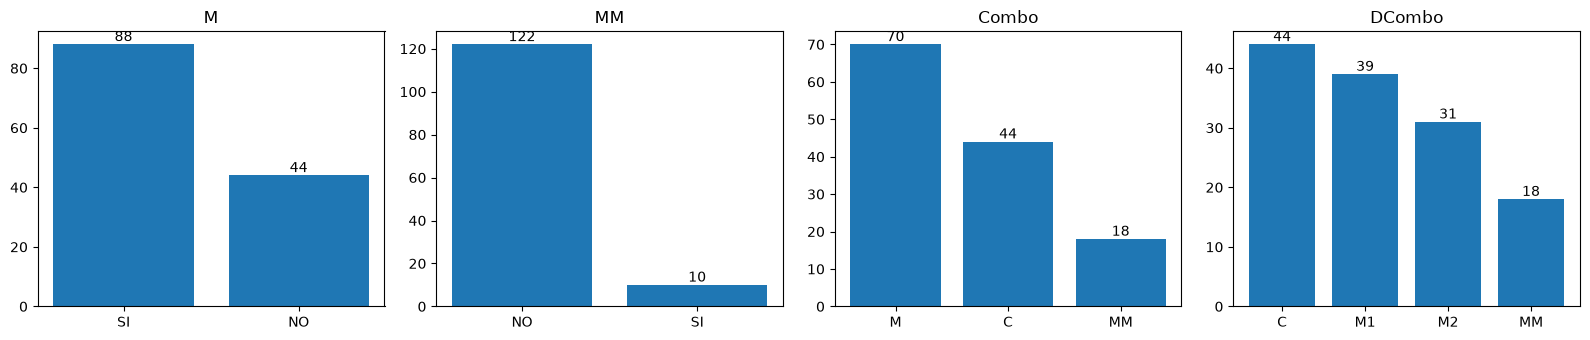

In [10]:
fig, axes = plt.subplots(1, 4, figsize=(16, 3.5))
for ax, col in zip(axes, Y_t.columns):
    vc = Y_t[col].value_counts()
    ax.bar(vc.index.astype(str), vc.values)
    for i, v in enumerate(vc.values):
        ax.text(i, v, v, ha='center', va='bottom')
    ax.set_title(col)
plt.tight_layout()
plt.show()

We see that the data for MM is skewed since there are a lot more negatives than positives

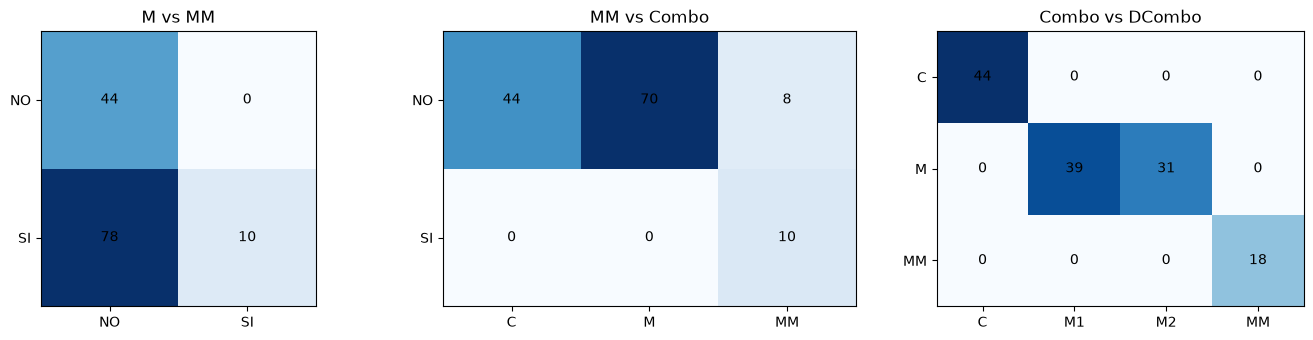

In [11]:
def heat(ct, ax, title):
    ax.imshow(ct.values, cmap='Blues')
    ax.set_xticks(range(ct.shape[1])); ax.set_xticklabels(ct.columns)
    ax.set_yticks(range(ct.shape[0])); ax.set_yticklabels(ct.index)
    for i in range(ct.shape[0]):
        for j in range(ct.shape[1]):
            ax.text(j, i, ct.values[i, j], ha='center', va='center')
    ax.set_title(title)

fig, axes = plt.subplots(1, 3, figsize=(14, 3.5))
heat(pd.crosstab(Y_t['M'], Y_t['MM']), axes[0], 'M vs MM')
heat(pd.crosstab(Y_t['MM'], Y_t['Combo']), axes[1], 'MM vs Combo')
heat(pd.crosstab(Y_t['Combo'], Y_t['DCombo']), axes[2], 'Combo vs DCombo')
plt.tight_layout()
plt.show()

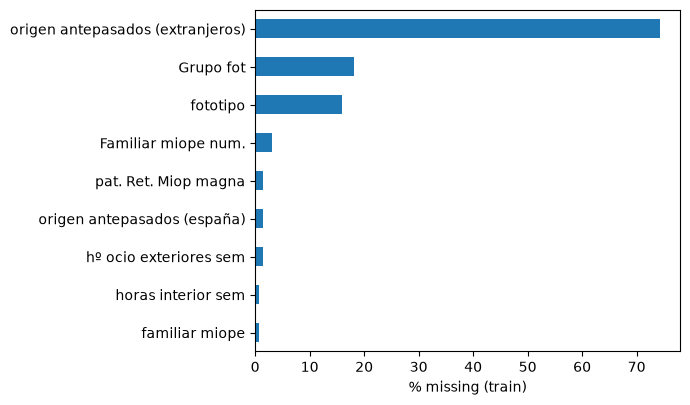

In [12]:
miss = (X_t.isna().mean() * 100).sort_values()
miss = miss[miss > 0]
ax = miss.plot.barh(figsize=(7, 0.35 * len(miss) + 1))
ax.set_xlabel('% missing (train)')
plt.tight_layout()
plt.show()

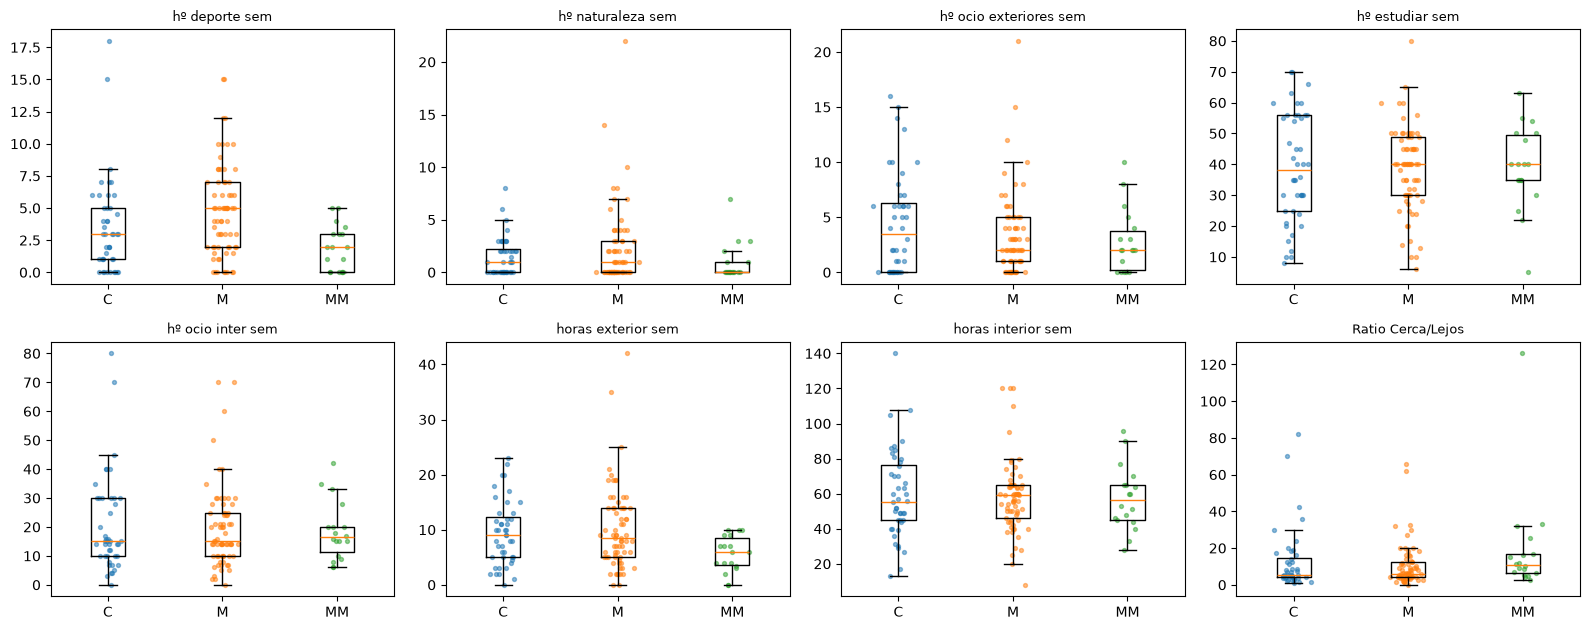

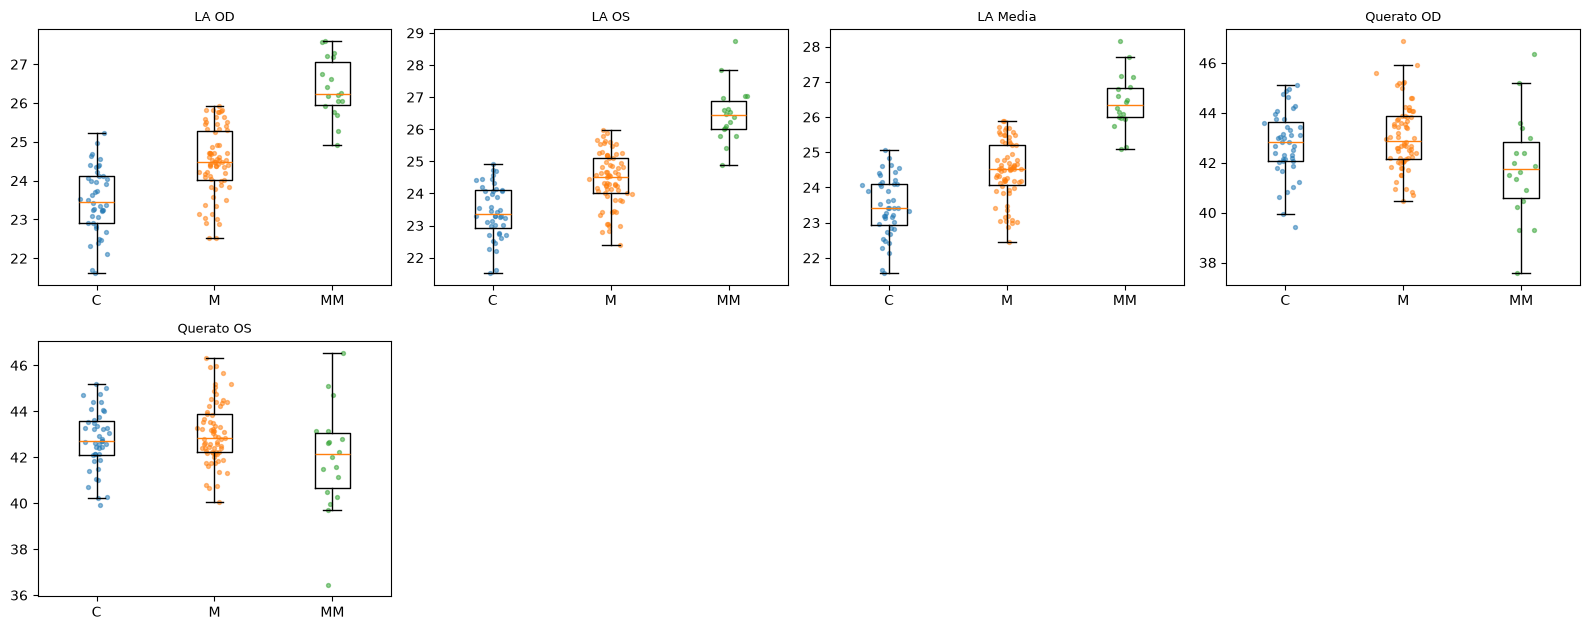

In [13]:
def box_by_class(cols, target, order, ncols=4):
    nrows = int(np.ceil(len(cols) / ncols))
    fig, axes = plt.subplots(nrows, ncols, figsize=(4 * ncols, 3.2 * nrows))
    axes = np.atleast_1d(axes).ravel()
    rng = np.random.default_rng(0)
    for ax, c in zip(axes, cols):
        data = [X_t.loc[Y_t[target] == k, c].dropna() for k in order]
        ax.boxplot(data, showfliers=False)
        for i, d in enumerate(data, start=1):
            ax.scatter(rng.normal(i, 0.06, len(d)), d, s=8, alpha=0.5)
        ax.set_xticks(range(1, len(order) + 1))
        ax.set_xticklabels(order)
        ax.set_title(c, fontsize=9)
    for ax in axes[len(cols):]:
        ax.axis('off')
    plt.tight_layout()
    plt.show()

box_by_class(hours, 'Combo', ['C', 'M', 'MM'])
box_by_class(biometry, 'Combo', ['C', 'M', 'MM'])

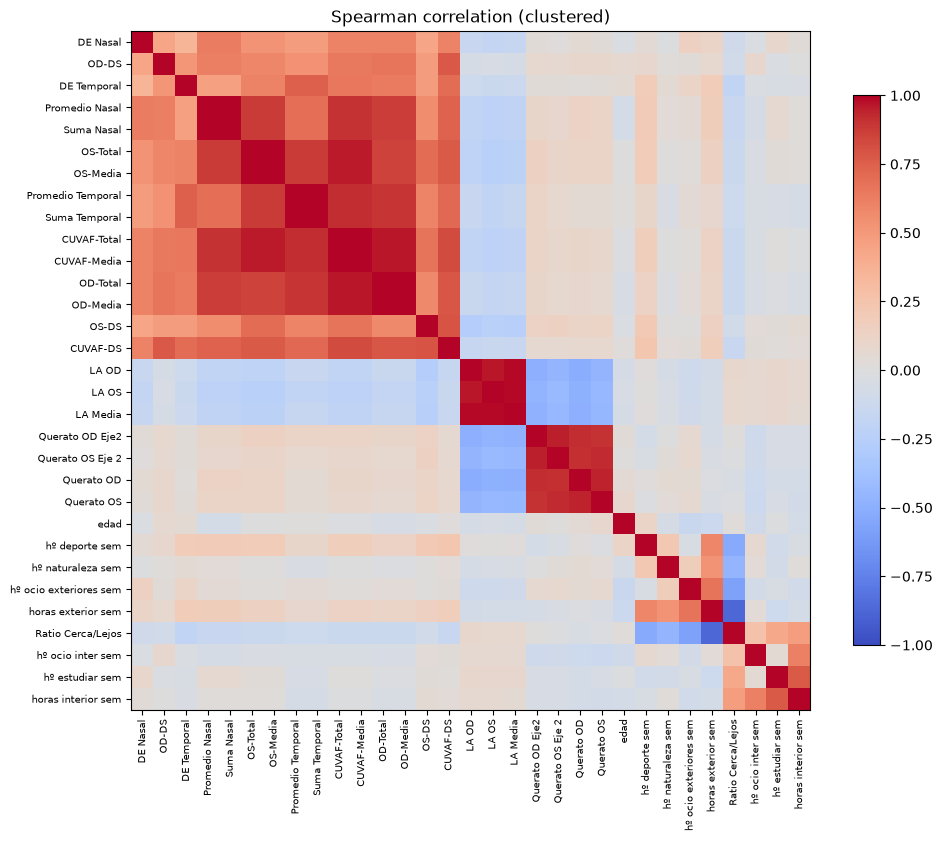

In [14]:
from scipy.cluster.hierarchy import linkage, leaves_list
from scipy.spatial.distance import squareform

corr = X_t[cont_cols].corr(method='spearman')
d = (1 - corr.abs()).fillna(1).to_numpy(copy=True)   # writable copy
np.fill_diagonal(d, 0)
d = (d + d.T) / 2
order = leaves_list(linkage(squareform(d, checks=False), 'average'))
corr = corr.iloc[order, order]

fig, ax = plt.subplots(figsize=(10, 9))
im = ax.imshow(corr.values, cmap='coolwarm', vmin=-1, vmax=1)
ax.set_xticks(range(len(corr))); ax.set_xticklabels(corr.columns, rotation=90, fontsize=7)
ax.set_yticks(range(len(corr))); ax.set_yticklabels(corr.columns, fontsize=7)
fig.colorbar(im, ax=ax, shrink=0.7)
ax.set_title('Spearman correlation (clustered)')
plt.tight_layout()
plt.show()

In [15]:
X_t.drop(columns=["origen antepasados (extranjeros)"], inplace=True)

/var/folders/j_/csb44tdj46q5z7vld9q7xss80000gn/T/ipykernel_6315/289857384.py:1: Pandas4Warning: The inplace keyword in DataFrame.drop is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  X_t.drop(columns=["origen antepasados (extranjeros)"], inplace=True)


In [16]:
X_t.drop(columns=["Grupo fot"], inplace=True)
X_t.drop(columns=["fototipo"], inplace=True)

/var/folders/j_/csb44tdj46q5z7vld9q7xss80000gn/T/ipykernel_6315/4293025515.py:1: Pandas4Warning: The inplace keyword in DataFrame.drop is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  X_t.drop(columns=["Grupo fot"], inplace=True)
/var/folders/j_/csb44tdj46q5z7vld9q7xss80000gn/T/ipykernel_6315/4293025515.py:2: Pandas4Warning: The inplace keyword in DataFrame.drop is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  X_t.drop(columns=["fototipo"], inplace=True)


In [17]:
X_t.drop(columns=["origen antepasados (españa)"], inplace=True)

/var/folders/j_/csb44tdj46q5z7vld9q7xss80000gn/T/ipykernel_6315/2319858102.py:1: Pandas4Warning: The inplace keyword in DataFrame.drop is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  X_t.drop(columns=["origen antepasados (españa)"], inplace=True)


In [18]:
X_t["sexo"] = X_t["sexo"].replace({'Mujer': 1, 'Hombre': 0})
X_t["fumador"] = X_t["fumador"].replace({'SI': 1, 'NO': 0})

In [19]:
list(X_t.columns)

['edad',
 'sexo',
 'hº deporte sem',
 'hº naturaleza sem',
 'hº ocio exteriores sem',
 'horas exterior sem',
 'hº estudiar sem',
 'hº ocio inter sem',
 'horas interior sem',
 'Ratio Cerca/Lejos',
 'Exterior Mucho',
 'Interior Mcho',
 'familiar miope',
 'Familiar miope num.',
 'Familiar MM SI/NO',
 'familiar miope magno',
 'pat. Ret. Miop magna',
 'fumador',
 'toma sol',
 'protege sol',
 'disp.elec.antes dormir',
 'LA OD',
 'LA OS',
 'LA Media',
 'Querato OD',
 'Querato OD Eje2',
 'Querato OS',
 'Querato OS Eje 2',
 'OD-Total',
 'OD-Media',
 'OD-DS',
 'OS-Total',
 'OS-Media',
 'OS-DS',
 'CUVAF-Total',
 'CUVAF-Media',
 'CUVAF-DS',
 'Promedio Nasal',
 'DE Nasal',
 'Suma Nasal',
 'Promedio Temporal',
 'DE Temporal',
 'Suma Temporal']

In [20]:
X_test=pd.read_csv("data/X_test.csv")

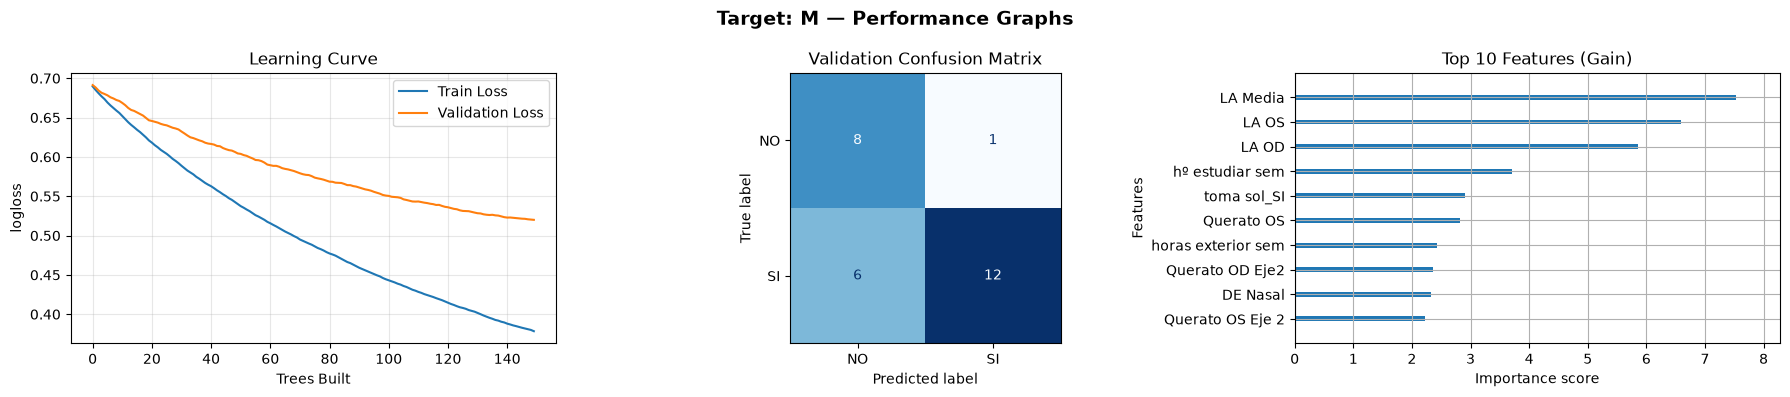

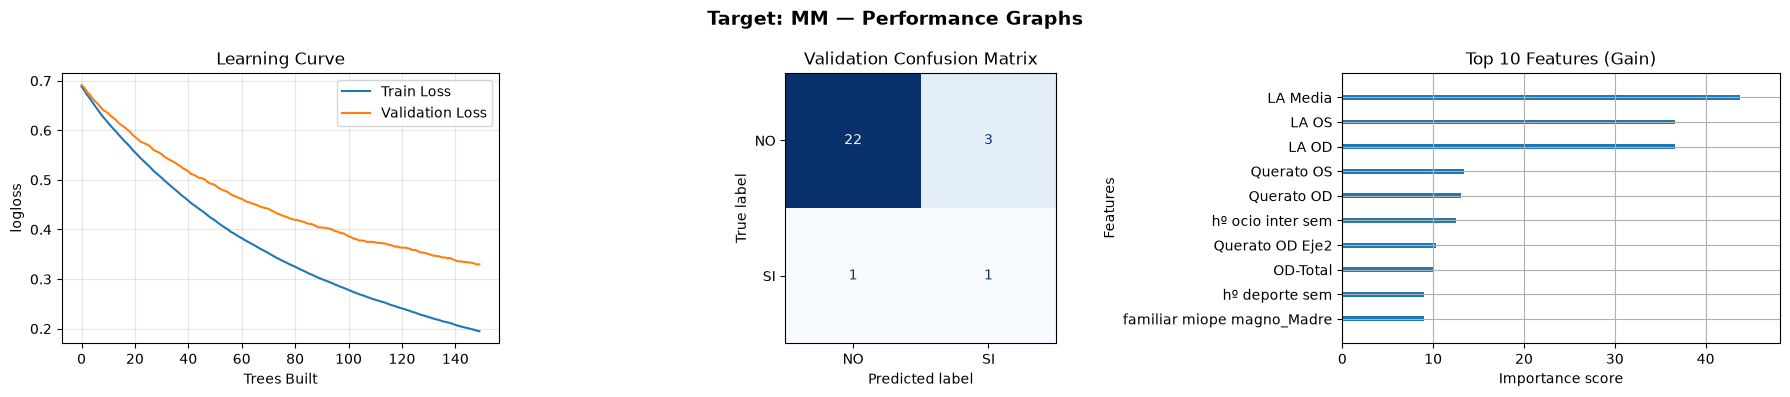

/Users/alex/src/ML-Miopia/.ML/lib/python3.13/site-packages/xgboost/training.py:200: UserWarning: [18:05:10] WARNING: /Users/runner/work/xgboost/xgboost/src/learner.cc:794: 
Parameters: { "scale_pos_weight" } are not used.

  bst.update(dtrain, iteration=i, fobj=obj)


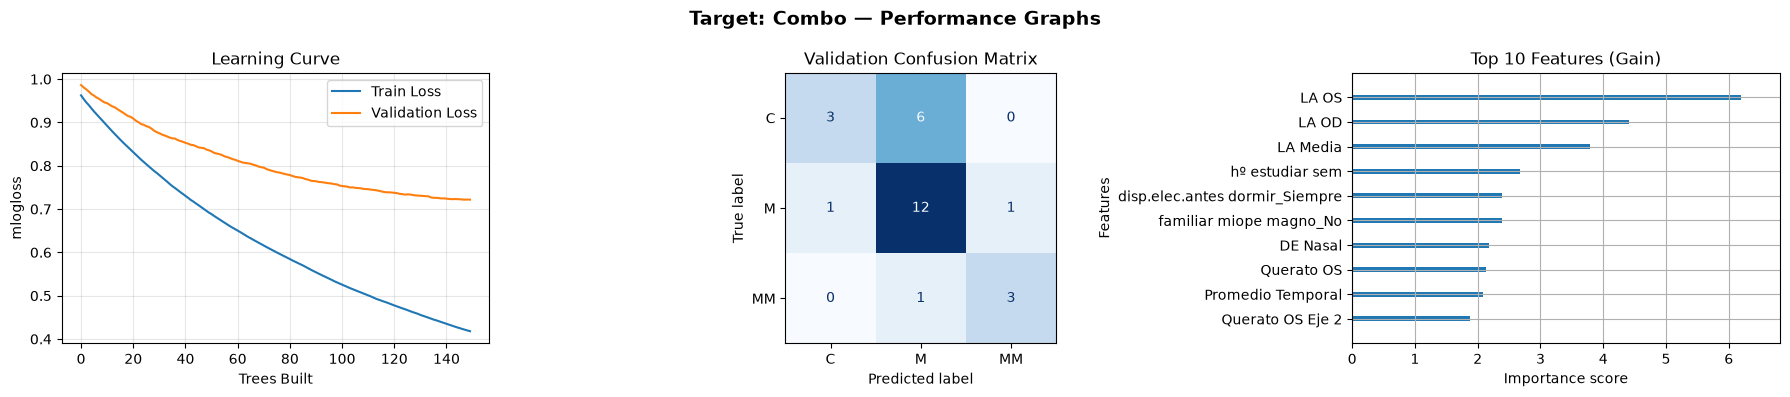

/Users/alex/src/ML-Miopia/.ML/lib/python3.13/site-packages/xgboost/training.py:200: UserWarning: [18:05:11] WARNING: /Users/runner/work/xgboost/xgboost/src/learner.cc:794: 
Parameters: { "scale_pos_weight" } are not used.

  bst.update(dtrain, iteration=i, fobj=obj)
/Users/alex/src/ML-Miopia/.ML/lib/python3.13/site-packages/xgboost/training.py:200: UserWarning: [18:05:11] WARNING: /Users/runner/work/xgboost/xgboost/src/learner.cc:794: 
Parameters: { "scale_pos_weight" } are not used.

  bst.update(dtrain, iteration=i, fobj=obj)


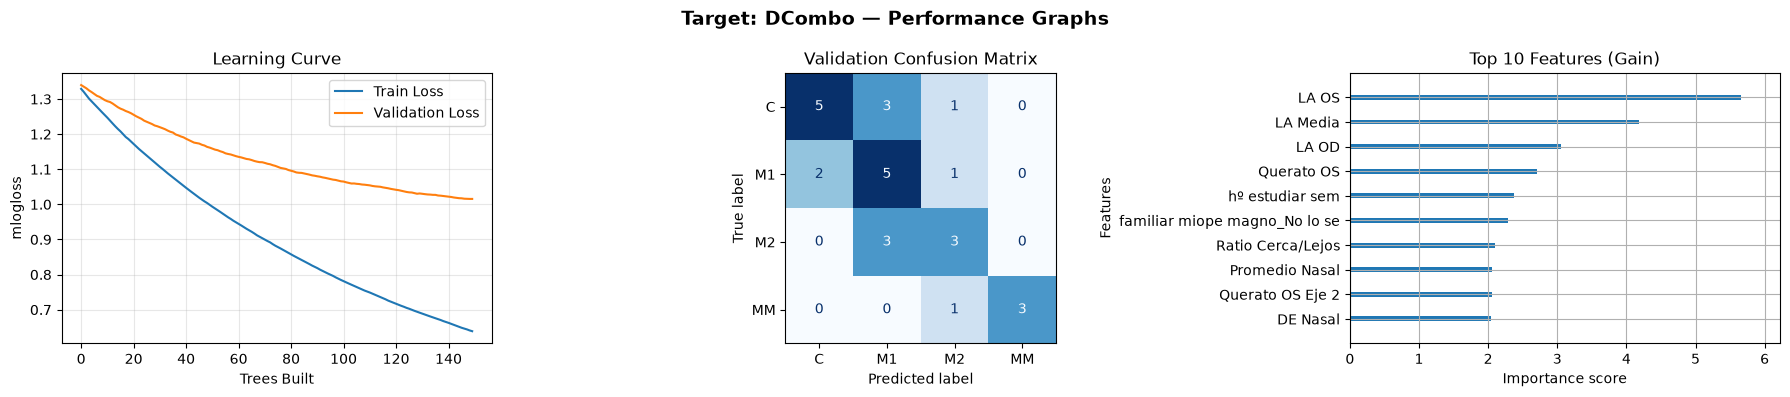

/Users/alex/src/ML-Miopia/.ML/lib/python3.13/site-packages/xgboost/training.py:200: UserWarning: [18:05:12] WARNING: /Users/runner/work/xgboost/xgboost/src/learner.cc:794: 
Parameters: { "scale_pos_weight" } are not used.

  bst.update(dtrain, iteration=i, fobj=obj)


In [21]:
import pandas as pd
import matplotlib.pyplot as plt
from xgboost import XGBClassifier, plot_importance
from sklearn.preprocessing import LabelEncoder
from sklearn.model_selection import train_test_split
from sklearn.metrics import ConfusionMatrixDisplay

# 1. Automatically extract target names directly from Y_t columns
targets = Y_t.columns.tolist()

# 2. One-hot encode categorical features across X_t (train) and X_test (unlabelled test)
X_all = pd.get_dummies(pd.concat([X_t, X_test], axis=0), drop_first=True)
X_tr = X_all.iloc[:len(X_t)]
X_te = X_all.iloc[len(X_t):]

results = {}

# 3. Train XGBoost model and plot performance per target
for target in targets:
    le = LabelEncoder()
    y_tr = le.fit_transform(Y_t[target])
    
    # Validation split for performance evaluation before test prediction
    X_train_sub, X_val, y_train_sub, y_val = train_test_split(
        X_tr, y_tr, test_size=0.2, random_state=42, stratify=y_tr
    )
    
    eval_metric = 'logloss' if len(le.classes_) == 2 else 'mlogloss'

    if len(le.classes_) == 2:
        num_neg = (y_tr == 0).sum()
        num_pos = (y_tr == 1).sum()
        pos_weight = num_neg / num_pos if num_pos > 0 else 1.0
    else:
        pos_weight = 1.0
    
    model = XGBClassifier(
        n_estimators=150,
        learning_rate=0.01,
        max_depth=3,
        eval_metric=eval_metric,
        scale_pos_weight=pos_weight,  # <-- Penalizes missing rare YES cases
        random_state=42,
        subsample=0.8
    )
    
    # Track training vs validation performance
    model.fit(
        X_train_sub, y_train_sub,
        eval_set=[(X_train_sub, y_train_sub), (X_val, y_val)],
        verbose=False
    )
    
    # --- GRAPH GENERATION (3 Graphs Per Target) ---
    fig, axes = plt.subplots(1, 3, figsize=(18, 4))
    fig.suptitle(f'Target: {target} — Performance Graphs', fontsize=14, fontweight='bold')
    
    # 1. Learning Curve (Train vs Validation Loss)
    evals = model.evals_result()
    axes[0].plot(evals['validation_0'][eval_metric], label='Train Loss')
    axes[0].plot(evals['validation_1'][eval_metric], label='Validation Loss')
    axes[0].set_title('Learning Curve')
    axes[0].set_xlabel('Trees Built')
    axes[0].set_ylabel(eval_metric)
    axes[0].legend()
    axes[0].grid(True, alpha=0.3)
    
    # 2. Validation Confusion Matrix
    y_val_pred = model.predict(X_val)
    ConfusionMatrixDisplay.from_predictions(
        y_val, y_val_pred, 
        display_labels=le.classes_, 
        ax=axes[1], 
        cmap='Blues', 
        colorbar=False
    )
    axes[1].set_title('Validation Confusion Matrix')
    
    # 3. Top 10 Feature Importances (Gain)
    plot_importance(model, max_num_features=10, ax=axes[2], importance_type='gain', show_values=False)
    axes[2].set_title('Top 10 Features (Gain)')
    
    plt.tight_layout()
    plt.show()
    
    # Re-fit model on FULL training set (X_tr, y_tr) to make final predictions on X_test
    model.fit(X_tr, y_tr, verbose=False)
    preds = model.predict(X_te)
    results[target] = le.inverse_transform(preds)

# 4. Build predictions DataFrame and enforce domain rules
test_preds = pd.DataFrame(results, index=X_test.index)

# Robust target column matching (handles 'Combo' vs 'COMBO')
combo_col = [c for c in test_preds.columns if c.upper() == 'COMBO'][0]

test_preds.loc[test_preds['MM'] == 'YES', 'M'] = 'YES'
test_preds.loc[test_preds['MM'] == 'YES', combo_col] = 'MM'
test_preds.loc[test_preds['M'] == 'NO', combo_col] = 'C'

# Save predictions to CSV file
test_preds.to_csv('test_predictions.csv', index=False)

<Figure size 1000x800 with 0 Axes>

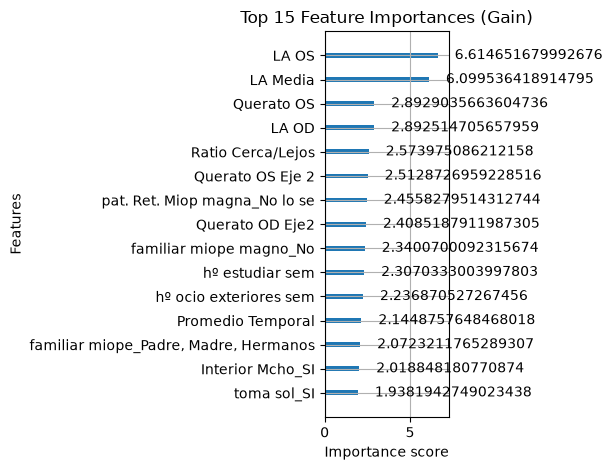

In [22]:
from xgboost import plot_importance

plt.figure(figsize=(10, 8))
# 'gain' measures the average improvement in accuracy brought by a feature
plot_importance(model, max_num_features=15, importance_type='gain', title='Top 15 Feature Importances (Gain)')
plt.tight_layout()
plt.show()

/Users/alex/src/ML-Miopia/.ML/lib/python3.13/site-packages/sklearn/svm/_base.py:236: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(
/Users/alex/src/ML-Miopia/.ML/lib/python3.13/site-packages/sklearn/svm/_base.py:236: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(
/Users/alex/src/ML-Miopia/.ML/lib/python3.13/site-packages/sklearn/svm/_base.py:236: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(
/Users/alex/src/ML-Miopia/.ML/lib/python3.13/site-packages/sklearn/svm/_base.py:236: FutureWarning: The `probability` parameter

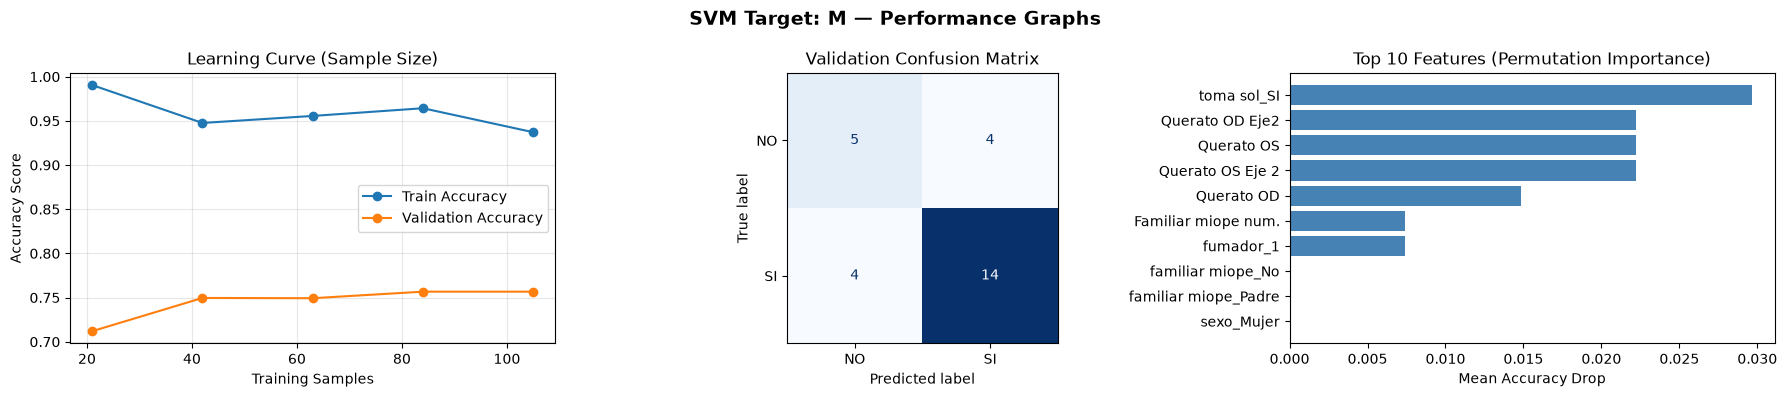

/Users/alex/src/ML-Miopia/.ML/lib/python3.13/site-packages/sklearn/svm/_base.py:236: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(
/Users/alex/src/ML-Miopia/.ML/lib/python3.13/site-packages/sklearn/svm/_base.py:236: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(
/Users/alex/src/ML-Miopia/.ML/lib/python3.13/site-packages/sklearn/svm/_base.py:236: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(
/Users/alex/src/ML-Miopia/.ML/lib/python3.13/site-packages/sklearn/svm/_base.py:236: FutureWarning: The `probability` parameter

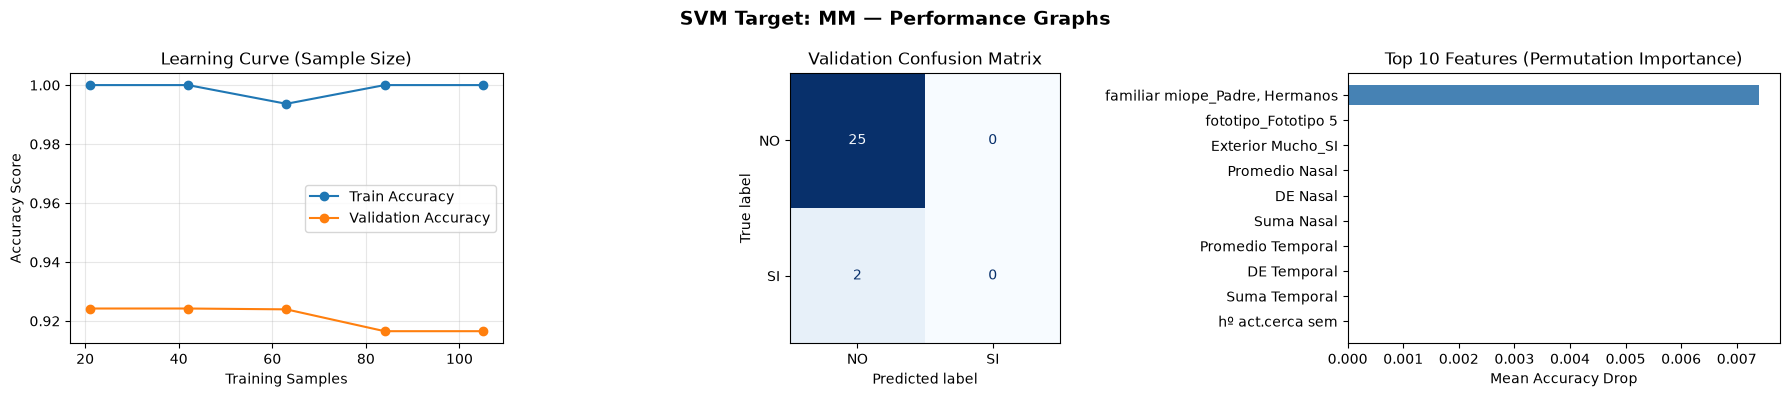

/Users/alex/src/ML-Miopia/.ML/lib/python3.13/site-packages/sklearn/svm/_base.py:236: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(
/Users/alex/src/ML-Miopia/.ML/lib/python3.13/site-packages/sklearn/svm/_base.py:236: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(
/Users/alex/src/ML-Miopia/.ML/lib/python3.13/site-packages/sklearn/svm/_base.py:236: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(
/Users/alex/src/ML-Miopia/.ML/lib/python3.13/site-packages/sklearn/svm/_base.py:236: FutureWarning: The `probability` parameter

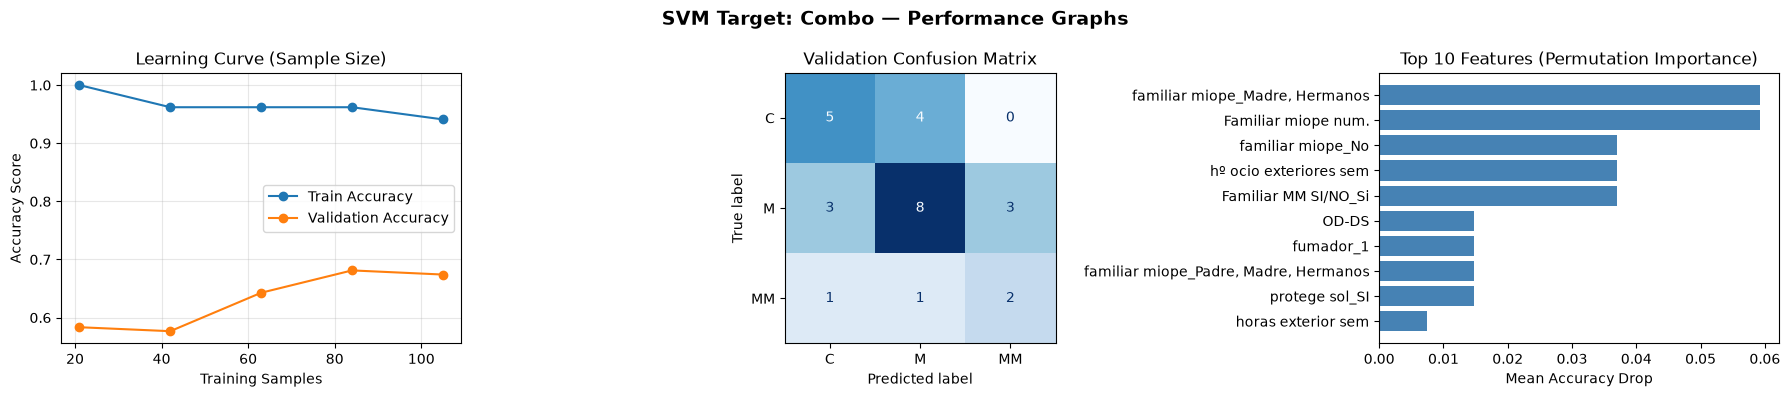

/Users/alex/src/ML-Miopia/.ML/lib/python3.13/site-packages/sklearn/svm/_base.py:236: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(
/Users/alex/src/ML-Miopia/.ML/lib/python3.13/site-packages/sklearn/svm/_base.py:236: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(
/Users/alex/src/ML-Miopia/.ML/lib/python3.13/site-packages/sklearn/svm/_base.py:236: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(
/Users/alex/src/ML-Miopia/.ML/lib/python3.13/site-packages/sklearn/svm/_base.py:236: FutureWarning: The `probability` parameter

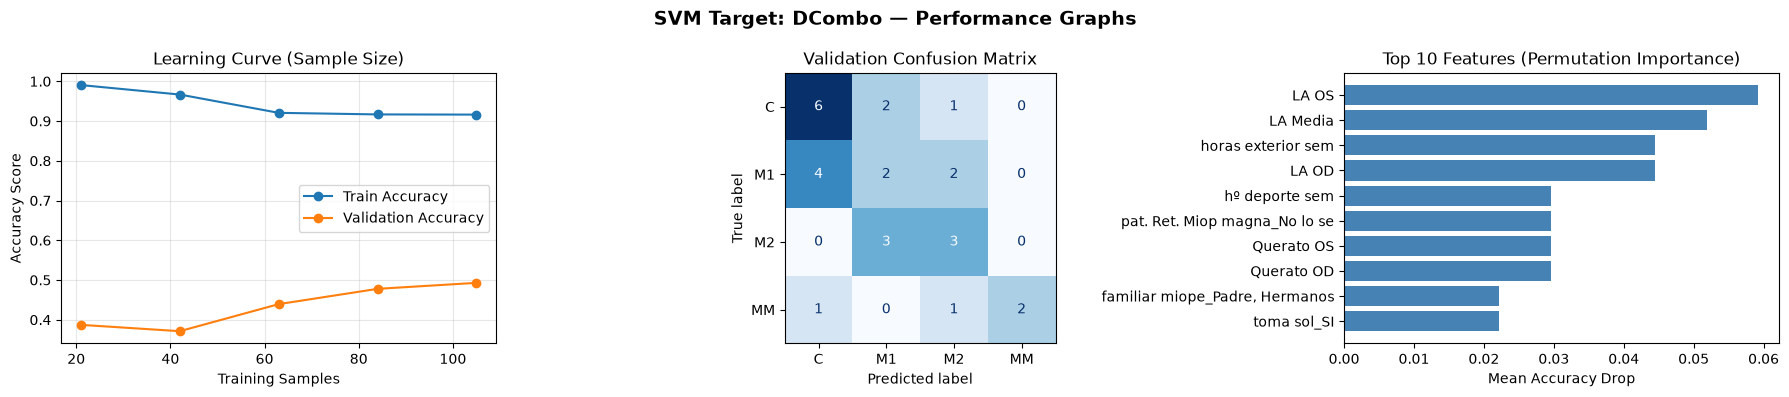

/Users/alex/src/ML-Miopia/.ML/lib/python3.13/site-packages/sklearn/svm/_base.py:236: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(


In [23]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.svm import SVC
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.model_selection import train_test_split, learning_curve
from sklearn.metrics import ConfusionMatrixDisplay
from sklearn.inspection import permutation_importance

# 1. Target names from Y_t
targets = Y_t.columns.tolist()

# 2. One-hot encode categorical features across X_t and X_test
X_all = pd.get_dummies(pd.concat([X_t, X_test], axis=0), drop_first=True)

# 3. SVM requires handling missing values and feature scaling
imputer = SimpleImputer(strategy='median', keep_empty_features=True)
scaler = StandardScaler()

# Configure transformers to directly output DataFrames with aligned columns and index
imputer.set_output(transform="pandas")
scaler.set_output(transform="pandas")

# Transform entire dataset cleanly
X_all_scaled = scaler.fit_transform(imputer.fit_transform(X_all))

X_tr = X_all_scaled.iloc[:len(X_t)]
X_te = X_all_scaled.iloc[len(X_t):]

results = {}

# 4. Train SVM model and generate performance plots for each target
for target in targets:
    le = LabelEncoder()
    y_tr = le.fit_transform(Y_t[target])
    
    # Train/validation split for evaluation
    X_train_sub, X_val, y_train_sub, y_val = train_test_split(
        X_tr, y_tr, test_size=0.2, random_state=42, stratify=y_tr
    )
    
    # RBF-kernel Support Vector Classifier with balanced class weights
    model = SVC(
        kernel='rbf',
        C=1.0,
        gamma='scale',
        class_weight='balanced',
        probability=True,
        random_state=42
    )
    
    model.fit(X_train_sub, y_train_sub)
    
    # --- GRAPH GENERATION (3 Graphs Per Target) ---
    fig, axes = plt.subplots(1, 3, figsize=(18, 4))
    fig.suptitle(f'SVM Target: {target} — Performance Graphs', fontsize=14, fontweight='bold')
    
    # 1. Learning Curve (Accuracy vs. Training Sample Size)
    train_sizes, train_scores, val_scores = learning_curve(
        model, X_tr, y_tr, 
        train_sizes=np.linspace(0.2, 1.0, 5), 
        cv=5, 
        scoring='accuracy',
        random_state=42
    )
    axes[0].plot(train_sizes, train_scores.mean(axis=1), 'o-', label='Train Accuracy')
    axes[0].plot(train_sizes, val_scores.mean(axis=1), 'o-', label='Validation Accuracy')
    axes[0].set_title('Learning Curve (Sample Size)')
    axes[0].set_xlabel('Training Samples')
    axes[0].set_ylabel('Accuracy Score')
    axes[0].legend()
    axes[0].grid(True, alpha=0.3)
    
    # 2. Validation Confusion Matrix
    y_val_pred = model.predict(X_val)
    ConfusionMatrixDisplay.from_predictions(
        y_val, y_val_pred, 
        display_labels=le.classes_, 
        ax=axes[1], 
        cmap='Blues', 
        colorbar=False
    )
    axes[1].set_title('Validation Confusion Matrix')
    
    # 3. Top 10 Permutation Feature Importances
    perm_importance = permutation_importance(model, X_val, y_val, n_repeats=5, random_state=42)
    sorted_idx = perm_importance.importances_mean.argsort()[-10:]
    axes[2].barh(X_tr.columns[sorted_idx], perm_importance.importances_mean[sorted_idx], color='steelblue')
    axes[2].set_title('Top 10 Features (Permutation Importance)')
    axes[2].set_xlabel('Mean Accuracy Drop')
    
    plt.tight_layout()
    plt.show()
    
    # Re-fit model on FULL training set (X_tr, y_tr) to make final test predictions
    model.fit(X_tr, y_tr)
    preds = model.predict(X_te)
    results[target] = le.inverse_transform(preds)

# 5. Build predictions DataFrame and enforce domain rules
test_preds = pd.DataFrame(results, index=X_test.index)

combo_col = [c for c in test_preds.columns if c.upper() == 'COMBO'][0]

test_preds.loc[test_preds['MM'] == 'YES', 'M'] = 'YES'
test_preds.loc[test_preds['MM'] == 'YES', combo_col] = 'MM'
test_preds.loc[test_preds['M'] == 'NO', combo_col] = 'C'

# Save predictions to CSV file
test_preds.to_csv('test_predictions_svm.csv', index=False)